### **Project Objective**

The primary objective of this project is to understand and apply **sentiment analysis techniques** on real-world social media data. By using comments from an Instagram post, the goal is to analyze user opinions and classify them into **positive, negative, and neutral sentiments**.

This project also aims to:

* Gain hands-on experience with **data extraction from social media platforms**
* Perform **data cleaning and preprocessing** on unstructured text data
* Apply **Natural Language Processing (NLP)** techniques for sentiment classification
* Derive meaningful insights about **audience engagement and perception**

---

### **Methodology**

The project was carried out in the following steps:

**1. Data Collection**
Comments were collected from a personal Instagram post with over ~2000 comments. Initially, a Chrome extension (*IG Comments Exporter*) was used, but due to its limitation of extracting only ~200 comments, an alternative approach was adopted.
Using the browser’s **developer console** and JavaScript, comments were successfully extracted directly from the webpage.

**2. Data Preparation**
The extracted data was saved and processed into a structured format (Excel).
Unnecessary elements such as duplicates, system-generated text (e.g., “reply”, “likes”), and noise were removed to obtain a clean dataset of **691 comments**.

**3. Data Processing**
The cleaned dataset was imported into Python using libraries like **pandas**.
Basic preprocessing steps such as trimming text and handling missing values were performed.

**4. Sentiment Analysis**
Sentiment analysis was applied using NLP techniques (TextBlob), where each comment was assigned a **sentiment score** and classified into:

* Positive
* Negative
* Neutral

**5. Data Visualization**
The results were visualized using graphs (bar chart and pie chart) to understand the distribution of sentiments across all comments.

**6. Insight Generation**
Based on the analysis, it was observed that most comments were neutral, while positive comments were significantly higher than negative ones. This indicates that the audience perception of the content is generally favorable.


Dataset shape: (5517, 10)
Columns: ['comment_id', 'user_id', 'username', 'text', 'created_at', 'likes', 'folder_name', 'sub_folder_name', 'predicted_sentiment_label', 'predicted_sentiment_score']
          comment_id      user_id           username  \
0  17898394511483558  44529525301   __cosm_ic_soul__   
1  17951499439417572   8421790331       __smejkalova   
2  17860730717275121  44896985790         milodagger   
3  17931813829421983  32525844356       bendeniz.mlk   
4  17908075042525104  34886596619  glitched_out10101   

                                                text           created_at  \
0                            Millie🔥🔥Steve Aoki dj😍😍  2021-10-27 08:17:58   
1                                 Omg i Love mills 😍  2021-03-05 23:09:09   
2                                          👏👏👏👏👏 wao  2020-11-26 14:14:46   
3  @agucakseser Çoğu kişi biliyor ki Miquelanın a...  2020-11-02 18:16:42   
4  : team galaxy!!! i have a samsung galaxy 8 and...  2020-10-05 19:31:35   

   l

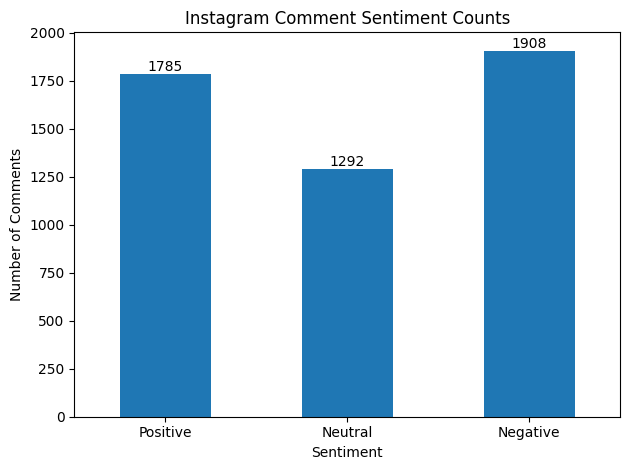

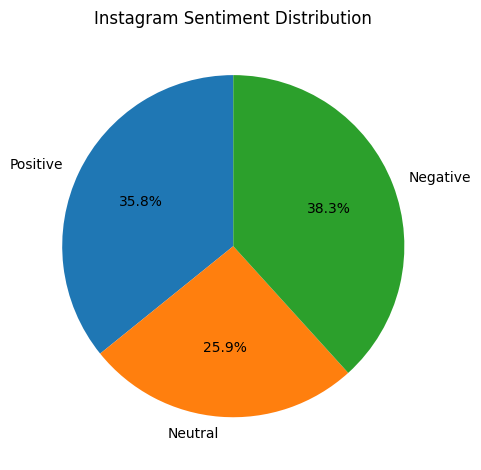


Analysis completed successfully.
Output saved to: C:\Users\shett\Downloads\instagram_sentiment_analysis_cleaned.csv


In [7]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob

# ==========================================
# 1. LOAD DATASET
# ==========================================

FILE_PATH = Path("sentiment-labels.csv")

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {FILE_PATH.resolve()}. "
        "Place sentiment-labels.csv in the working directory."
    )

df = pd.read_csv(FILE_PATH)
df.columns = [str(col).strip() for col in df.columns]

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())










# ==========================================
# 5. SENTIMENT ANALYSIS SUMMARY
# ==========================================

sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

total = int(sentiment_counts.sum())

if total == 0:
    raise ValueError(
        "No valid sentiment labels available for analysis."
    )

sentiment_percentages = (
    sentiment_counts / total * 100
).round(2)

summary = pd.DataFrame({
    "Count": sentiment_counts.astype(int),
    "Percentage": sentiment_percentages
})

print("\nTotal comments analyzed:", total)
print("\nSentiment Analysis Results:")
print(summary)


# ==========================================
# 6. BAR CHART
# ==========================================

ax = sentiment_counts.plot(kind="bar", rot=0)

ax.set_title("Instagram Comment Sentiment Counts")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Comments")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()


# ==========================================
# 7. PIE CHART
# ==========================================

nonzero_counts = sentiment_counts[
    sentiment_counts > 0
]

if not nonzero_counts.empty:
    nonzero_counts.plot(
        kind="pie",
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        title="Instagram Sentiment Distribution"
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 8. EXPORT RESULTS
# ==========================================

OUTPUT_FILE = Path(
    "instagram_sentiment_analysis_cleaned.csv"
)

df.to_csv(OUTPUT_FILE, index=False)

print("\nAnalysis completed successfully.")
print("Output saved to:", OUTPUT_FILE.resolve())


In [11]:
# ==========================================
# 2. IDENTIFY COMMENT AND SENTIMENT COLUMNS
# ==========================================

def find_column(candidates):
    columns = {col.lower(): col for col in df.columns}
    for candidate in candidates:
        if candidate.lower() in columns:
            return columns[candidate.lower()]
    return None


text_col = find_column([
    "text", "comment", "comments", "comment_text", "message"
])

label_col = find_column([
    "predicted_sentiment_label",
    "sentiment",
    "sentiment_label",
    "label"
])

score_col = find_column([
    "predicted_sentiment_score",
    "sentiment_score",
    "polarity",
    "score"
])

if text_col is None:
    raise ValueError(
        "Comment column not found. Available columns: "
        + str(df.columns.tolist())
    )

rename_map = {text_col: "comment"}

if label_col:
    rename_map[label_col] = "sentiment"

if score_col:
    rename_map[score_col] = "sentiment_score"

df = df.rename(columns=rename_map)
df = df.loc[:, ~df.columns.duplicated()].copy()

In [9]:
# ==========================================
# 3. CLEAN DATA
# ==========================================

rows_before = len(df)

df = df.dropna(subset=["comment"]).copy()
df["comment"] = df["comment"].astype(str).str.strip()
df = df[df["comment"] != ""].copy()

df = df.drop_duplicates(subset=["comment"]).reset_index(drop=True)

print("\nRows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("\nMissing values:")
print(df.isnull().sum())


Rows before cleaning: 4985
Rows after cleaning: 4985

Missing values:
comment_id         0
user_id            0
username           0
comment            0
created_at         0
likes              0
folder_name        0
sub_folder_name    0
sentiment          0
sentiment_score    0
dtype: int64


In [10]:
# ==========================================
# 4. SENTIMENT CLASSIFICATION
# ==========================================

def normalize_sentiment(value):
    if pd.isna(value):
        return None

    value = str(value).strip().lower()

    labels = {
        "positive": "Positive",
        "pos": "Positive",
        "negative": "Negative",
        "neg": "Negative",
        "neutral": "Neutral",
        "neu": "Neutral"
    }

    return labels.get(value)


if "sentiment" in df.columns:
    df["sentiment"] = df["sentiment"].apply(
        normalize_sentiment
    )
else:
    df["sentiment"] = None


# Use TextBlob if there are no usable sentiment labels.
if df["sentiment"].notna().sum() == 0:

    df["sentiment_score"] = df["comment"].apply(
        lambda text: TextBlob(text).sentiment.polarity
    )

    def classify_sentiment(score):
        if score > 0.05:
            return "Positive"
        elif score < -0.05:
            return "Negative"
        else:
            return "Neutral"

    df["sentiment"] = df["sentiment_score"].apply(
        classify_sentiment
    )

else:
    df = df.dropna(subset=["sentiment"]).copy()

    if "sentiment_score" in df.columns:
        df["sentiment_score"] = pd.to_numeric(
            df["sentiment_score"], errors="coerce"
        )

print("\nSentiment classification completed.")
print(df[["comment", "sentiment"]].head())



Sentiment classification completed.
                                             comment sentiment
0                            Millie🔥🔥Steve Aoki dj😍😍  Positive
1                                 Omg i Love mills 😍  Positive
2                                          👏👏👏👏👏 wao  Positive
3  @agucakseser Çoğu kişi biliyor ki Miquelanın a...  Negative
4  : team galaxy!!! i have a samsung galaxy 8 and...  Positive


In [12]:
# ==========================================
# 5. SENTIMENT ANALYSIS SUMMARY
# ==========================================

sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

total = int(sentiment_counts.sum())

if total == 0:
    raise ValueError(
        "No valid sentiment labels available for analysis."
    )

sentiment_percentages = (
    sentiment_counts / total * 100
).round(2)

summary = pd.DataFrame({
    "Count": sentiment_counts.astype(int),
    "Percentage": sentiment_percentages
})

print("\nTotal comments analyzed:", total)
print("\nSentiment Analysis Results:")
print(summary)


Total comments analyzed: 4985

Sentiment Analysis Results:
           Count  Percentage
sentiment                   
Positive    1785       35.81
Neutral     1292       25.92
Negative    1908       38.27


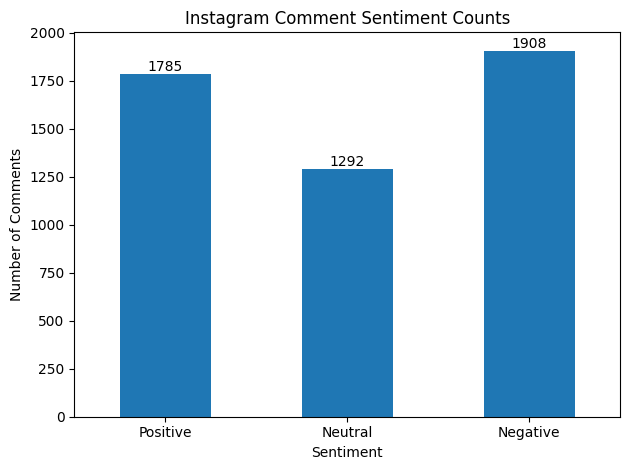

In [13]:
# ==========================================
# 6. BAR CHART
# ==========================================

ax = sentiment_counts.plot(kind="bar", rot=0)

ax.set_title("Instagram Comment Sentiment Counts")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Comments")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()


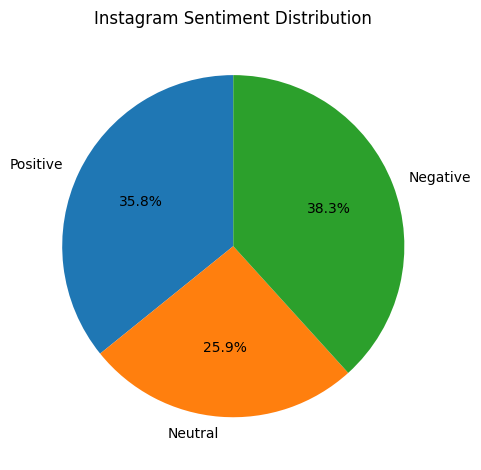

In [14]:
# ==========================================
# 7. PIE CHART
# ==========================================

nonzero_counts = sentiment_counts[
    sentiment_counts > 0
]

if not nonzero_counts.empty:
    nonzero_counts.plot(
        kind="pie",
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        title="Instagram Sentiment Distribution"
    )

    plt.tight_layout()
    plt.show()



In [15]:
# ==========================================
# 8. EXPORT RESULTS
# ==========================================

OUTPUT_FILE = Path(
    "instagram_sentiment_analysis_cleaned.csv"
)

df.to_csv(OUTPUT_FILE, index=False)

print("\nAnalysis completed successfully.")
print("Output saved to:", OUTPUT_FILE.resolve())



Analysis completed successfully.
Output saved to: C:\Users\shett\Downloads\instagram_sentiment_analysis_cleaned.csv


### **Conclusion**

This project highlights the practical application of sentiment analysis on real-world social media data. It demonstrates how user-generated content can be analyzed to understand audience behavior, engagement patterns, and overall sentiment toward digital content.
